### this script plots the authorship representation

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gp
import matplotlib.colors as colors
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

In [28]:
authorship_norm_path="../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/pub_author_reshuffled.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/Nature-Index/index_cleaned.csv'

In [29]:
authorship_norm_plot_path='../../data/dropbox/LaborDivision/figs/authorship_normed.pdf'
authorship_norm_plot_legend_path='../../data/dropbox/LaborDivision/figs/authorship_normed_legend.pdf'
authorship_norm_ann_plot_path='../../data/dropbox/LaborDivision/figs/authorship_normed_annual.pdf'

In [2]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
stgroup_df=pd.read_csv(stgroup_path)
stgroup_df.head()

,Code,class
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [31]:
stgroup_df.loc[stgroup_df['Code']=='MYS','ST']='Proficient'
stgroup_df.loc[stgroup_df['Code']=='VNM','ST']='Proficient'
stgroup_df.loc[stgroup_df['Code']=='SAU','ST']='Proficient'

In [7]:
alltime=norm_df.groupby(['cntry','role']).agg({'raw':'sum','shuffle':'sum'}).reset_index() #group over years

In [8]:
alltime['ratio']=alltime['raw']/alltime['shuffle']

In [9]:
alltime = alltime.pivot(index='cntry',columns='role',values='ratio')

In [10]:
alltime.head()

role,F,L,M
cntry,,,
ABW,0.805369,0.653595,1.152416
AFG,0.761006,0.650773,1.120397
AGO,0.774992,0.656057,1.109443
ALB,0.985133,0.682231,1.075764
AND,1.225383,0.669643,1.020690


In [11]:
def map_group(fratio,lratio):
    if fratio<1 and lratio<1:
        return 0.5
    elif fratio>1 and lratio<1:
        return 1.5
    elif fratio<1 and lratio>1:
        return 2.5
    elif fratio>1 and lratio>1:
        return 3.5
alltime['group']=alltime.apply(lambda x:map_group(x.F,x.L),axis=1)

In [12]:
colorsList = ['#A6A6A6', '#F4D05E', '#EA6B5F','#912855']
cmap = colors.ListedColormap(colorsList)
bounds = np.array([0, 1, 2, 3, 4])
norm = colors.BoundaryNorm(boundaries=bounds, ncolors=4)

In [13]:
world_geo=gp.read_file("../../data/dropbox/LaborDivision/Data/additionaldata/worldmap/ne_50m_admin_0_countries.shp")

In [14]:
world_geo.loc[world_geo.NAME=='France','ISO_A3']='FRA'
world_geo.loc[world_geo.NAME=='Norway','ISO_A3']='NOR'
world_geo = world_geo[['ADMIN','NAME','ISO_A3','geometry']]
world_geo=world_geo[world_geo.NAME!='Antarctica']

In [15]:
world_geo.head()

,ADMIN,NAME,ISO_A3,geometry
0,Zimbabwe,Zimbabwe,ZWE,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Zambia,ZMB,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Yemen,YEM,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."
3,Vietnam,Vietnam,VNM,"MULTIPOLYGON (((104.06396 10.39082, 104.08301 ..."
4,Venezuela,Venezuela,VEN,"MULTIPOLYGON (((-60.82119 9.13838, -60.94141 9..."


In [16]:
alltime=alltime.reset_index()

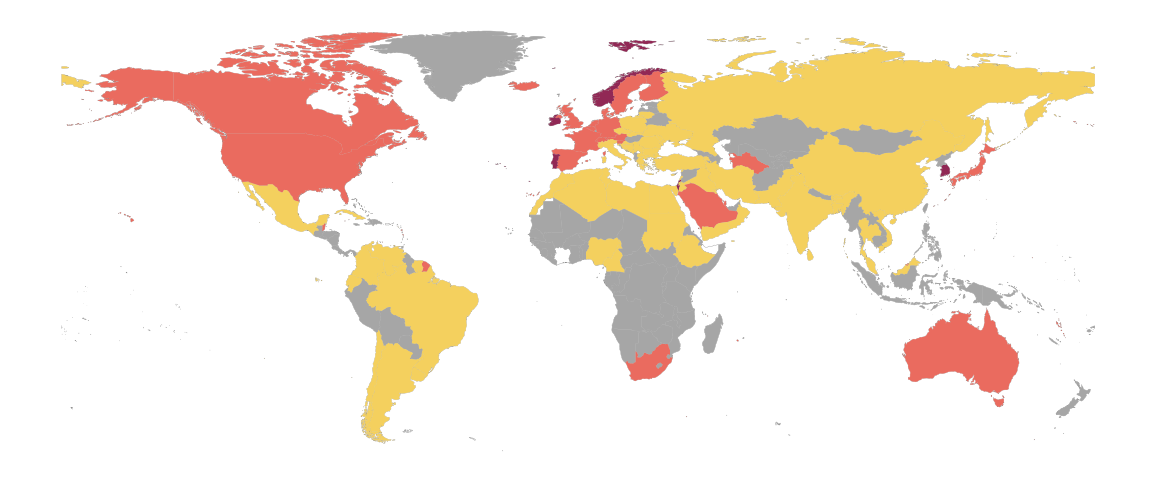

In [17]:
fig, ax=plt.subplots(figsize=(16,6))
world_geo.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
ax.axis("off")
df = alltime.merge(world_geo,left_on='cntry',right_on='ISO_A3')
df = gp.GeoDataFrame(df)
df.plot(column='group', cmap=cmap, norm=norm,vmin=0.9, vmax=1.1, ax=ax)
gray_patch = mpatches.Patch(color='#A6A6A6',label='Under_first;Under_last')
yellow_patch = mpatches.Patch(color='#F4D05E',label='Over_first;Under_last')
pink_patch = mpatches.Patch(color='#EA6B5F',label='Under_first;Over_last')
red_patch = mpatches.Patch(color='#912855',label='Over_first;Over_last')

plt.savefig(authorship_norm_plot_path,bbox_inches='tight')

In [19]:
alltime[alltime.group==3.5]

role,cntry,F,L,M,group
84,IRL,1.020411,1.081609,0.980037,3.5
88,ISR,1.069431,1.075746,0.974026,3.5
99,KOR,1.027480,1.083908,0.980148,3.5
136,NOR,1.000659,1.044665,0.991654,3.5
148,PRT,1.057888,1.008727,0.988592,3.5


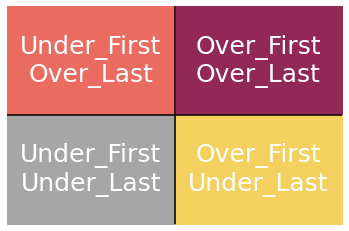

In [9]:
import matplotlib.pyplot as plt

# create a figure and axis object
fig, ax = plt.subplots()

# set the limits of the x and y axis
ax.set_xlim([-5, 5])
ax.set_ylim([-5, 5])

# draw the x and y axis
ax.axhline(y=0, color='black')
ax.axvline(x=0, color='black')

# fill the four quadrants with different colors
ax.fill_betweenx(y=[0, 5], x1=0, x2=5, color='#912855')
ax.text(2.5, 2.5, 'Over_First\nOver_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[0, 5], x1=-5, x2=0, color='#EA6B5F')
ax.text(-2.5, 2.5, 'Under_First\nOver_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[-5, 0], x1=0, x2=5, color='#F4D05E')
ax.text(2.5, -2.5, 'Over_First\nUnder_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[-5, 0], x1=-5, x2=0, color='#A6A6A6')
ax.text(-2.5, -2.5, 'Under_First\nUnder_Last', ha='center', va='center',fontsize=25, c='white')

ax.set_xticks([])
ax.set_yticks([])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.savefig(authorship_norm_plot_legend_path,bbox_inches='tight')

In [3]:
def get_normed_authorship(raw_df, exp_df):
    cntry_raw = raw_df.groupby(['cntry','year','role']).size().reset_index(name='raw')
    cntry_exp = exp_df.groupby(['cntry','year','role'])['expected'].sum().reset_index(name='exp')
    cntry_all = cntry_raw.merge(cntry_exp, on=['cntry','year','role'])
    cntry_all['norm'] = np.log(cntry_all['raw']/cntry_all['exp'])
    #cntry_norm = cntry_all.pivot(index='cntry', columns='role', values='norm').reset_index()
    
    return cntry_all

In [4]:
pub_author_raw_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/pub_author.csv"
pub_author_exp_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/pub_author_expected.csv"
pub_author_raw = pd.read_csv(pub_author_raw_path)
pub_author_exp = pd.read_csv(pub_author_exp_path)

In [5]:
cntry_norm = get_normed_authorship(pub_author_raw, pub_author_exp)

In [6]:
cntry_norm = cntry_norm.merge(stgroup_df, left_on='cntry', right_on='Code')

In [7]:
cntry_norm.head()

,cntry,year,role,raw,exp,norm,Code,class
0,ABW,2014,M,1,0.90,0.105361,ABW,Lagging
1,ABW,2016,M,4,1.85,0.771109,ABW,Lagging
2,ABW,2017,F,1,2.10,-0.741937,ABW,Lagging
3,ABW,2017,M,9,6.65,0.302608,ABW,Lagging
4,ABW,2018,F,1,0.50,0.693147,ABW,Lagging


In [8]:
cntry_norm['class'].unique()

array(['Lagging', 'Developing', 'Advanced', 'Proficient'], dtype=object)

In [10]:
color_scheme = pd.read_csv('../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/color_scheme.csv')
color_scheme

,class,color,type
0,Advanced,#D96C94,st
1,Proficient,#F88A4D,st
2,Developing,#5DC97C,st
3,Lagging,#23A5D9,st
4,High,#D96C94,income
5,Upper-middle,#F88A4D,income
6,Lower-middle,#5DC97C,income
7,Low,#23A5D9,income


In [11]:
color_filter = color_scheme[color_scheme.type=='st']
color_dict = dict(zip(color_filter['class'], color_filter['color']))
color_dict

{'Advanced': '#D96C94',
 'Proficient': '#F88A4D',
 'Developing': '#5DC97C',
 'Lagging': '#23A5D9'}

In [17]:
color_dict.keys()

dict_keys(['Advanced', 'Proficient', 'Developing', 'Lagging'])

In [32]:
def plot_line(data,authorship,ax,title,color_dict):

    df=data[data.role==authorship]
    sns.lineplot(x='year',y='norm',hue='class',data=df,ax=ax,legend=False,
             palette=color_dict)
    ax.axhline(y=0, color='#C8C8C8', linestyle='--')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title,fontsize=12)
    ax.set_ylim(-0.45, 0.15)
    return ax

Text(0.45, 0.01, 'Year of publication')

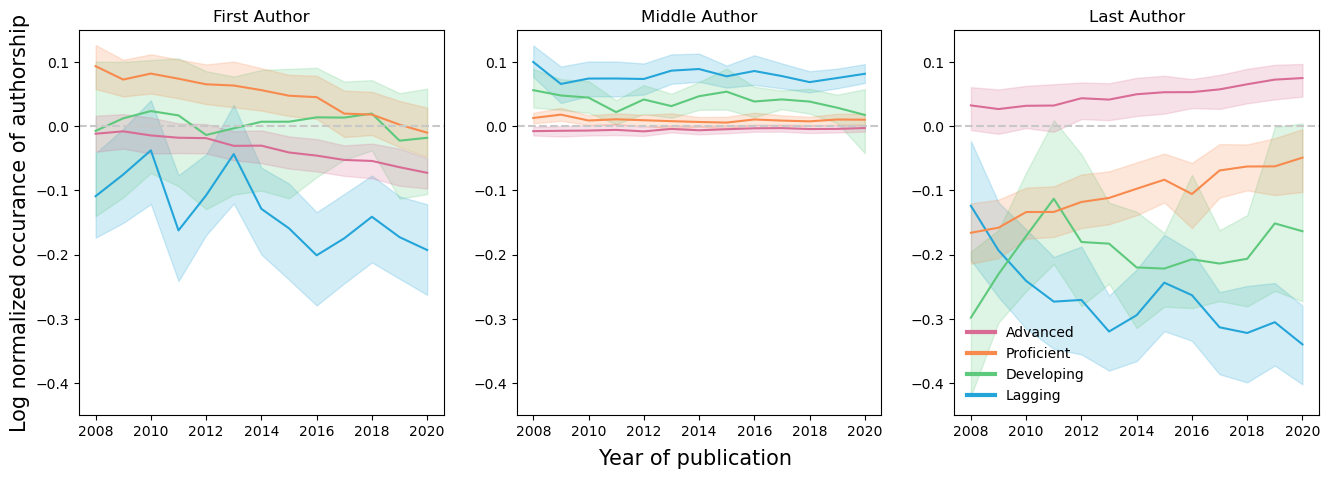

In [33]:
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(16,5))
ax0=plot_line(cntry_norm,'F',ax[0],'First Author', color_dict)
ax0.set_ylabel("Log normalized occurance of authorship",fontsize=15)
ax1=plot_line(cntry_norm,'M',ax[1],'Middle Author', color_dict)
ax2=plot_line(cntry_norm,'L',ax[2],'Last Author', color_dict)

lines = [Line2D([0], [0], color=v, linewidth=3, linestyle='-', label=k) for k,v in color_dict.items()]

plt.legend(handles = lines, frameon=False)
fig.text(x=0.45,y=0.01,s="Year of publication",fontsize=15)
#plt.savefig(authorship_norm_ann_plot_path,bbox_inches='tight')

In [14]:
lines = [Line2D([0], [0], color=v, linewidth=3, linestyle='-', label=k) for k,v in color_dict.items()]

In [16]:
lines[0]

In [26]:
cntry_norm[(cntry_norm.group=='H')&(cntry_norm.role=='L')&(cntry_norm.year==2010)].sort_values(by='norm')

,cntry,year,role,raw,exp,norm,code,group
2723,IRN,2010,L,734,1280.15,-0.556224,IRN,H
6418,VNM,2010,L,131,227.25,-0.550853,VNM,H
6223,UKR,2010,L,388,562.15,-0.370763,UKR,H
4634,PAK,2010,L,416,578.40,-0.329580,PAK,H
5862,THA,2010,L,655,879.20,-0.294377,THA,H
1115,CHN,2010,L,9446,12300.95,-0.264085,CHN,H
5091,RUS,2010,L,1651,2134.65,-0.256922,RUS,H
6067,TUR,2010,L,905,1117.65,-0.211049,TUR,H
2645,IND,2010,L,2631,3126.50,-0.172550,IND,H
1783,EST,2010,L,143,167.65,-0.159034,EST,H
